![Banner](../images/09_03_banner_rs_rader.png)


# NISAR GSLC: Geocoded Single Look Complex Processing

This notebook reads the NISAR Level-2 GSLC scene over coastal Bangladesh, subsets it to `AOI_coastal.geojson`, and creates geocoded HH/HV amplitude, intensity, phase, and dual-polarization RGB quick looks with GeoLattice.


## Overview

GSLC is a complex radar product on a map-projected grid, so it retains phase while removing the radar-coordinate geometry handling required for RSLC.


## Core concepts

### Learning objectives

1. Inspect the GSLC product with `nisar.read_identification` and `nisar.inspect_hdf5`, including the frequencyA geocoded grid and EPSG code.
2. Select the row and column window for `AOI_coastal.geojson` from `xCoordinates` and `yCoordinates` in the product CRS.
3. Stream HH and HV in bounded chunks and multilook each block to a complex mean (phase) and a mean of `|S|^2` (intensity).
4. Lee-filter linear intensity, convert it to dB for display, and plot wrapped phase separately from displacement.
5. Attach the product CRS and clip the downsampled layers to the exact AOI polygon.
6. Build an HH/HV false-color RGB (red = HH dB, green = HV dB, blue = HH-HV dB) for visual interpretation only.
7. Explain why this intensity is not calibrated sigma0 or gamma0, and when GCOV or a multi-date InSAR workflow is the right product.

### Contents

1. Processing overview and limitations
2. Inspect the product and geocoded grid
3. Select the AOI window
4. Stream and multilook the complex GSLC
5. Amplitude, intensity, and phase
6. Attach the CRS and clip to the exact AOI
7. HH/HV false-color RGB composite
8. Optionally export AOI quick looks
9. Summary, exercises and references


## Processing overview and limitations

The source HDF5 contains full-resolution 5 m complex HH and HV images, each about 4.5 billion pixels. This workflow first selects the AOI bounds using the GSLC map coordinate axes, then reads only that window in bounded chunks. A 20 × 20 complex average produces approximately 100 m visualization pixels while retaining a phase estimate; mean intensity is also calculated from the original complex samples before averaging.

This is an exploratory display workflow. The power shown is a GSLC intensity proxy, not a radiometrically calibrated sigma0 or terrain-flattened gamma0 product. Use the paired GCOV product for calibrated geocoded covariance/backscatter analysis. The RGB composite is independently stretched for display and is not quantitative. A single GSLC cannot provide interferometric displacement; that requires a co-registered pair with compatible geometry and a carefully processed interferogram.


**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Imports, plotting defaults, and locating the NISAR GSLC scene and AOI on disk.

# 1. Standard library and core scientific/geospatial stack. h5py reads the GSLC HDF5
#    directly (so we can stream only the AOI window instead of loading the full ~4.5
#    billion-pixel complex arrays), rioxarray registers the .rio accessor used later to
#    attach a CRS and clip, and leafmap renders the interactive AOI location check.
from pathlib import Path

import geopandas as gpd  # vector data (the AOI)
import h5py  # read NISAR HDF5 files
import leafmap  # interactive web maps
import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import rioxarray  # registers the .rio accessor
import xarray as xr  # labelled rasters

# 2. geolattice.rsense exposes shared raster helpers (Lee filtering, dB conversion); the
#    nisar submodule under geolattice.rsense.sar holds the NISAR-specific HDF5 readers used
#    below (read_identification, inspect_hdf5).
from geolattice import rsense as rs
from geolattice.rsense.sar import nisar  # NISAR helpers

# 3. A slightly higher display resolution for the figures drawn later in the notebook.
plt.rcParams.update({"figure.dpi": 110})

# 4. Resolve the data folder whether the notebook is run from the repository root or
#    from this tutorial's own directory, then build the path to the specific GSLC
#    granule (coastal Bangladesh) and its companion AOI polygon.
DATA_RELATIVE = Path("Data/08_remote_sensing/08_03_radar/NISAR_bd")
if not DATA_RELATIVE.exists():  # when run from the repository root instead of this folder
    DATA_RELATIVE = Path("../../../../Data/08_remote_sensing/08_03_radar/NISAR_bd")  # use the path from the root
DATA_DIR = DATA_RELATIVE  # the data folder
SCENE = DATA_DIR / (  # the GSLC file
    "NISAR_L2_PR_GSLC_031_069_A_013_4005_DHDH_A_20260922T232058_"
    "20260922T232133_P05023_N_F_J_001.h5"
)
AOI_PATH = DATA_DIR / "AOI_coastal.geojson"  # the coastal AOI polygon

# 5. Fail fast with a clear message if the sample data has not been downloaded, rather
#    than letting a later cell raise a confusing h5py/geopandas error.
assert SCENE.is_file(), f"NISAR GSLC file not found: {SCENE.resolve()}"
assert AOI_PATH.is_file(), f"AOI GeoJSON not found: {AOI_PATH.resolve()}"  # stop if the AOI file is missing

print(f"GeoLattice remote sensing version: {rs.__version__}")  # GeoLattice version
print(f"GSLC: {SCENE.name}")  # the GSLC file
print(f"AOI:  {AOI_PATH}")  # the AOI file

GeoLattice remote sensing version: 0.2.0.dev0
GSLC: NISAR_L2_PR_GSLC_031_069_A_013_4005_DHDH_A_20260922T232058_20260922T232133_P05023_N_F_J_001.h5
AOI:  data/NISAR_bd/AOI_coastal.geojson


## Inspect the product and geocoded grid

The NISAR product-level identification group describes the acquisition, while the GSLC `frequencyA` group contains complex polarization layers, the valid-sample mask, projected coordinates, and EPSG code. GeoLattice `inspect_hdf5` lists dataset metadata without loading the complete image.


In [2]:
# Inspect the product identification group and the frequencyA geocoded grid metadata.

# 1. read_identification pulls scalar acquisition metadata (mission, track/frame,
#    orbit direction, timing, DOI) from the product-level identification group without
#    touching the large image datasets. Print only the keys that are present, since
#    not every field is guaranteed to exist across product versions.
identification = nisar.read_identification(SCENE, "GSLC")
# list the datasets of the frequency-A grid
grid_info = nisar.inspect_hdf5(SCENE, "/science/LSAR/GSLC/grids/frequencyA")

for key in (  # identification fields to show
    "missionId", "productType", "productLevel", "productVersion",
    "trackNumber", "frameNumber", "orbitPassDirection", "lookDirection",
    "zeroDopplerStartTime", "zeroDopplerEndTime", "productDoi",
):
    if key in identification:  # print only the fields that are present
        print(f"{key}: {identification[key]}")  # field name and value

# 2. Open the frequencyA grid group directly to read the handful of attributes needed
#    to plan the AOI subset: the full image shape, which polarizations are present,
#    the projection EPSG code, the pixel spacing, and the 1-D map-grid coordinate axes.
#    Reading these small datasets does not load the full HH/HV complex arrays.
GRID = "/science/LSAR/GSLC/grids/frequencyA"
with h5py.File(SCENE, "r") as f:  # open the GSLC file
    grid = f[GRID]  # the frequency-A grid group
    image_shape = grid["HH"].shape  # size of the HH grid
    # polarisations of frequency A (decoded from bytes)
    polarizations = [v.decode() if isinstance(v, bytes) else str(v)
                     for v in grid["listOfPolarizations"][:]]
    epsg = int(grid["projection"][()])  # EPSG code of the map projection
    x_spacing = float(grid["xCoordinateSpacing"][()])  # pixel spacing in x (m)
    y_spacing = float(grid["yCoordinateSpacing"][()])  # pixel spacing in y (m, negative: north-up)
    x_axis = grid["xCoordinates"][:]  # x coordinate of every column
    y_axis = grid["yCoordinates"][:]  # y coordinate of every row
    print(f"Frequency A polarizations: {polarizations}")  # the polarisations
    print(f"Grid: {image_shape[0]:,} rows x {image_shape[1]:,} columns")  # grid size
    print(f"Grid CRS: EPSG:{epsg}; spacing: {x_spacing:g} m x {abs(y_spacing):g} m")  # CRS and pixel spacing

# 3. Summarize the dtype/shape of the datasets most relevant to the rest of the
#    notebook (the two polarization layers, the validity mask, and the coordinate
#    axes), pulled from the inspect_hdf5 listing gathered above.
[(path.rsplit("/", 1)[-1], info["shape"], info["dtype"])
 for path, info in grid_info.items()
 if path.rsplit("/", 1)[-1] in ("HH", "HV", "mask", "xCoordinates", "yCoordinates", "projection")]

missionId: NISAR
productType: GSLC
productLevel: L2
productVersion: 1.0.11
trackNumber: 69
frameNumber: 13
orbitPassDirection: Ascending
lookDirection: Left
zeroDopplerStartTime: 2026-09-22T23:20:58.000000000
zeroDopplerEndTime: 2026-09-22T23:21:33.999342105
productDoi: 10.5067/NIL2GSLC-P1
Frequency A polarizations: ['HH', 'HV']
Grid: 67,104 rows x 68,400 columns
Grid CRS: EPSG:32646; spacing: 5 m x 5 m


[('HH', (67104, 68400), 'complex64'),
 ('HV', (67104, 68400), 'complex64'),
 ('mask', (67104, 68400), 'uint8'),
 ('projection', (), 'uint32'),
 ('xCoordinates', (68400,), 'float64'),
 ('yCoordinates', (67104,), 'float64')]

## Select the AOI window

GSLC `xCoordinates` and `yCoordinates` are one-dimensional map-grid axes. Transform the GeoJSON AOI into the product CRS, locate rows and columns intersecting its projected bounds, and retain the precise polygon for a final clip. The interactive Leafmap below displays the AOI on Esri World Imagery; it is a visual location check, while the actual window is computed in the GSLC's projected CRS. Leafmap is included in the optional `geolattice[rsense-viz]` dependencies.


In [3]:
# Reproject the AOI into the GSLC's map CRS, find the matching row/column window, and
# show the AOI location on an imagery basemap for a visual sanity check.

# 1. Load the AOI polygon and make sure it carries a CRS (default to WGS84 if the
#    GeoJSON omits one). Keep a lon/lat copy for the Leafmap display and a copy
#    reprojected into the GSLC's own projected CRS (EPSG code read in the previous
#    cell) for the actual pixel-window computation.
aoi = gpd.read_file(AOI_PATH)
if aoi.crs is None:  # assume WGS 84 when the file has no CRS
    aoi = aoi.set_crs("EPSG:4326")  # set it
aoi_ll = aoi.to_crs("EPSG:4326")  # the AOI in longitude/latitude
aoi_grid = aoi.to_crs(f"EPSG:{epsg}")  # the AOI in the grid's projection
min_x, min_y, max_x, max_y = aoi_grid.total_bounds  # its bounding box

# 2. Because xCoordinates/yCoordinates are 1-D map-grid axes (not a 2-D geotransform),
#    the AOI's row/column window can be found directly by boolean-masking the axes
#    against the AOI's projected bounding box, rather than by any raster resampling.
row_indices = np.flatnonzero((y_axis >= min_y) & (y_axis <= max_y))
column_indices = np.flatnonzero((x_axis >= min_x) & (x_axis <= max_x))  # columns inside the AOI
if row_indices.size == 0 or column_indices.size == 0:  # no overlap
    raise ValueError("The AOI does not overlap the GSLC map grid")  # stop with a clear message
row_start, row_stop = int(row_indices[0]), int(row_indices[-1] + 1)  # first and last row (+1)
column_start, column_stop = int(column_indices[0]), int(column_indices[-1] + 1)  # first and last column (+1)
# AOI bounds in the grid CRS
print(f"AOI bounds in EPSG:{epsg}: {min_x:.1f}, {min_y:.1f}, {max_x:.1f}, {max_y:.1f}")
# the grid window
print(f"GSLC window: rows {row_start:,}:{row_stop:,}, columns {column_start:,}:{column_stop:,}")
print(f"Window size: {row_stop-row_start:,} x {column_stop-column_start:,} full-resolution pixels")  # its size

# 3. Render the AOI on an Esri World Imagery basemap purely as a visual location
#    check; this map is in geographic lon/lat and is independent of the projected
#    window computed above, which is what actually drives the HDF5 reads.
west, south, east, north = aoi_ll.total_bounds
center = ((south + north) / 2, (west + east) / 2)  # map centre (lat, lon)
aoi_map = leafmap.Map(center=center, zoom=8, height="600px")  # an interactive map
aoi_map.add_basemap("Esri.WorldImagery")  # satellite basemap
aoi_map.add_gdf(  # add the AOI polygon
    aoi_ll,
    layer_name="Coastal AOI",
    style={"color": "#ff3b30", "weight": 3, "fillColor": "#ff3b30", "fillOpacity": 0.12},
    hover_style={"color": "#ffff00", "weight": 4, "fillOpacity": 0.2},
    zoom_to_layer=False,
)
aoi_map.add_layer_control()  # layer switcher
aoi_map  # show the map

AOI bounds in EPSG:32646: 219364.0, 2420523.2, 351768.2, 2532569.9
GSLC window: rows 31,038:53,447, columns 20,833:47,314
Window size: 22,409 x 26,481 full-resolution pixels


Map(center=[np.float64(22.38019), np.float64(90.91958)], controls=(ZoomControl(options=['position', 'zoom_in_t…

## Stream and multilook the complex GSLC

Each output pixel is calculated from a small source block. `complex_mean` is the mean of valid complex samples and retains an averaged phase; `mean_power` is the mean of source `|S|²`, so it is not biased by phase cancellation. The GSLC mask is valid for values 1 to 254; 0 marks partially focused or invalid interpolation support and 255 is outside the acquisition. Set smaller looks for more detail at higher memory and display cost.


In [4]:
# Stream the AOI window from the HDF5 complex datasets in row-chunks and multilook it,
# producing both an averaged complex sample (for phase) and a mean power (for intensity).

# 1. LOOKS controls the multilook block size: 20 map-grid rows x 20 columns collapses
#    the ~5 m input pixels to roughly 100 m output pixels. OUTPUT_ROWS_PER_CHUNK caps
#    how many output rows are processed per HDF5 read, which bounds peak memory use
#    regardless of how large the AOI window is.
LOOKS = (20, 20)  # (map-grid rows, columns); 5 m input becomes about 100 m output
OUTPUT_ROWS_PER_CHUNK = 4  # multilooked rows computed per read

# multilooked complex values and power of a grid window, read chunk by chunk
def stream_complex_multilook(image_dataset, mask_dataset, window, looks=LOOKS,
                              output_rows_per_chunk=OUTPUT_ROWS_PER_CHUNK):
    """Return block-mean complex samples and mean source power from an HDF5 window."""
    # 2. Snap the requested window down to a whole number of look blocks in each
    #    dimension, since a partial block at the edge cannot be averaged consistently.
    row0, row1, col0, col1 = window
    look_y, look_x = looks  # looks in y and x
    out_rows = (row1 - row0) // look_y  # output rows
    out_columns = (col1 - col0) // look_x  # output columns
    if out_rows < 1 or out_columns < 1:  # window smaller than one look
        # stop with a clear message
        raise ValueError("AOI window is smaller than the selected multilook factors")
    row1 = row0 + out_rows * look_y  # trim to whole looks
    col1 = col0 + out_columns * look_x  # trim to whole looks
    # 3. Pre-allocate the full output arrays as NaN so any output pixel left without
    #    valid input samples is naturally flagged as missing rather than left at zero.
    complex_mean = np.full((out_rows, out_columns), np.nan + 1j * np.nan, dtype="complex64")
    mean_power = np.full((out_rows, out_columns), np.nan, dtype="float32")  # output power array

    # 4. Walk through the output rows in small chunks, reading only the corresponding
    #    band of source rows from the HDF5 dataset each time. This keeps the amount of
    #    full-resolution complex data held in memory at once small and constant,
    #    independent of the overall AOI size.
    for out0 in range(0, out_rows, output_rows_per_chunk):
        count = min(output_rows_per_chunk, out_rows - out0)  # output rows in this chunk
        source0 = row0 + out0 * look_y  # first source row
        source1 = source0 + count * look_y  # last source row
        samples = image_dataset[source0:source1, col0:col1]  # complex samples of the chunk
        mask = mask_dataset[source0:source1, col0:col1]  # the product's validity mask of the chunk
        # 5. The GSLC mask is valid for values 1-254; 0 marks partially focused or
        #    invalid interpolation support and 255 marks pixels outside the acquisition
        #    swath. Also drop any sample whose real/imaginary part is non-finite before
        #    it can contaminate a block average.
        valid = (mask > 0) & (mask < 255)
        valid &= np.isfinite(samples.real) & np.isfinite(samples.imag)  # also drop NaN samples
        # 6. Reshape each chunk so the look_y x look_x block for every output pixel
        #    becomes its own pair of axes, then reduce over just those axes.
        blocks = samples.reshape(count, look_y, out_columns, look_x)
        valid_blocks = valid.reshape(count, look_y, out_columns, look_x)  # validity per look block
        n_valid = valid_blocks.sum(axis=(1, 3))  # number of valid samples per block
        # 7. complex_sum/n_valid gives the mean complex sample (retains an averaged
        #    phase); power_sum/n_valid gives the mean of |S|^2 computed from the
        #    original complex samples, so it is not biased by phase cancellation the
        #    way |mean of S|^2 would be.
        complex_sum = np.where(valid_blocks, blocks, 0).sum(axis=(1, 3))
        # sum of the valid powers per block
        power_sum = np.where(valid_blocks, np.abs(blocks) ** 2, 0).sum(axis=(1, 3))
        complex_mean[out0:out0 + count] = np.divide(  # mean complex value per block
            complex_sum, n_valid, out=np.full_like(complex_sum, np.nan + 1j * np.nan),
            where=n_valid > 0,
        )
        mean_power[out0:out0 + count] = np.divide(  # mean power per block
            power_sum, n_valid, out=np.full_like(power_sum, np.nan, dtype="float32"),
            where=n_valid > 0,
        )
    return complex_mean, mean_power  # return both

# 8. Snap the AOI window from the earlier cell to a whole number of look blocks (the
#    same rule the function enforces internally), so the output row/column counts and
#    the window passed into the function agree exactly.
n_output_rows = (row_stop - row_start) // LOOKS[0]
n_output_columns = (column_stop - column_start) // LOOKS[1]  # output columns
row_stop = row_start + n_output_rows * LOOKS[0]  # trim to whole looks
column_stop = column_start + n_output_columns * LOOKS[1]  # trim to whole looks
window = (row_start, row_stop, column_start, column_stop)  # the final window

# 9. Run the chunked multilook for both HH and HV using the same AOI window and mask,
#    so the two polarizations end up on identical output grids.
with h5py.File(SCENE, "r") as f:
    grid = f[GRID]  # the frequency-A grid group
    hh_complex, hh_power = stream_complex_multilook(  # HH complex mean and power
        grid["HH"], grid["mask"], window
    )
    hv_complex, hv_power = stream_complex_multilook(  # HV complex mean and power
        grid["HV"], grid["mask"], window
    )

# 10. Build the output coordinate axes by averaging the original x/y axes within each
#     look block, so the multilooked arrays carry coordinates consistent with the
#     averaging that produced them. Report the overall valid-data fraction as a quick
#     quality check for this AOI.
out_x = x_axis[column_start:column_stop].reshape(n_output_columns, LOOKS[1]).mean(axis=1)
# y coordinate of every output row
out_y = y_axis[row_start:row_stop].reshape(n_output_rows, LOOKS[0]).mean(axis=1)
print(f"Multilooked array: {n_output_rows:,} rows x {n_output_columns:,} columns")  # output size
print(f"Valid HH output pixels: {np.isfinite(hh_power).mean():.1%}")  # valid HH share
print(f"Valid HV output pixels: {np.isfinite(hv_power).mean():.1%}")  # valid HV share

Multilooked array: 1,120 rows x 1,324 columns
Valid HH output pixels: 100.0%
Valid HV output pixels: 100.0%


## Amplitude, intensity, and phase

The mean source power is filtered with GeoLattice Lee filtering in linear units and converted to dB for display. Phase is computed from the averaged complex samples. Phase values are wrapped to (−π, π] and are not displacement: without a second acquisition, flat-earth/topographic removal, coherence weighting, unwrapping, and referencing, they cannot be interpreted as surface motion.


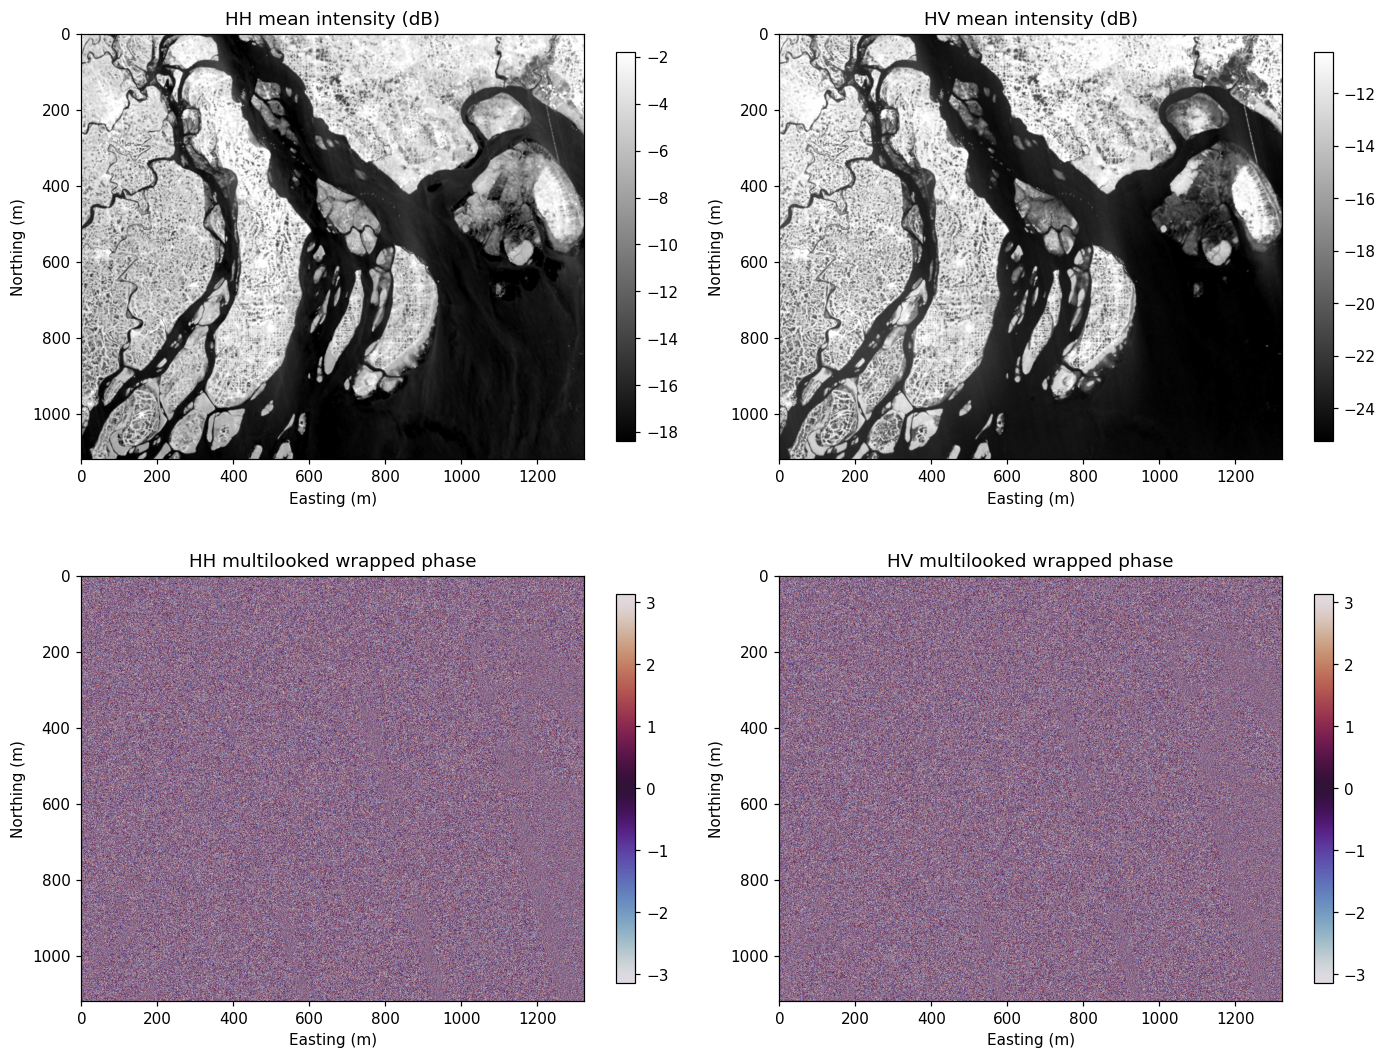

In [5]:
# Derive amplitude, intensity, and wrapped phase from the multilooked complex/power
# arrays, apply Lee speckle filtering and dB conversion to the intensities, and plot
# all four quick looks side by side.

# 1. Wrap the multilooked arrays as labeled xarray DataArrays on the averaged output
#    coordinates. Amplitude is sqrt(mean power); phase is the argument of the averaged
#    complex sample, which is only meaningful because the samples were averaged in the
#    complex domain (not from power alone).
coords = {"y": out_y, "x": out_x}
# HH intensity as a DataArray
hh_intensity = xr.DataArray(hh_power, dims=("y", "x"), coords=coords, name="hh_intensity")
hv_intensity = xr.DataArray(hv_power, dims=("y", "x"), coords=coords, name="hv_intensity")  # HV intensity
# HH amplitude = sqrt(power)
hh_amplitude = xr.DataArray(np.sqrt(hh_power), dims=("y", "x"), coords=coords, name="hh_amplitude")
# HV amplitude
hv_amplitude = xr.DataArray(np.sqrt(hv_power), dims=("y", "x"), coords=coords, name="hv_amplitude")
# HH wrapped phase of the averaged complex values
hh_phase = xr.DataArray(np.angle(hh_complex), dims=("y", "x"), coords=coords, name="hh_wrapped_phase")
# HV wrapped phase
hv_phase = xr.DataArray(np.angle(hv_complex), dims=("y", "x"), coords=coords, name="hv_wrapped_phase")

# 2. Apply GeoLattice's Lee speckle filter to the linear-units intensity (not to the dB or
#    the phase), then convert the filtered intensity to dB only for display. Filtering
#    before the log transform avoids distorting the speckle statistics the filter
#    assumes.
hh_filtered = xr.DataArray(rs.sar.lee(hh_intensity.values, size=5), dims=("y", "x"),
                           coords=coords, name="hh_filtered_intensity")
# Lee speckle filter on HV (5 x 5)
hv_filtered = xr.DataArray(rs.sar.lee(hv_intensity.values, size=5), dims=("y", "x"),
                           coords=coords, name="hv_filtered_intensity")
hh_db = rs.sar.to_db(hh_filtered)  # filtered HH in dB
hv_db = rs.sar.to_db(hv_filtered)  # filtered HV in dB

# 3. Plot filtered intensity (dB, percentile-stretched for contrast) next to wrapped
#    phase (fixed range -pi to pi, cyclic colormap) for each polarization. The
#    percentile stretch is a display choice only; the phase panels use a fixed range
#    because phase is inherently bounded.
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, image, title, cmap, limits in (  # the panels: image, title, colour map and limits
    (axes[0, 0], hh_db, "HH mean intensity (dB)", "gray", None),
    (axes[0, 1], hv_db, "HV mean intensity (dB)", "gray", None),
    (axes[1, 0], hh_phase, "HH multilooked wrapped phase", "twilight", (-np.pi, np.pi)),
    (axes[1, 1], hv_phase, "HV multilooked wrapped phase", "twilight", (-np.pi, np.pi)),
):
    if limits is None:  # no fixed limits: use a 2-98 % stretch
        vmin, vmax = np.nanpercentile(image.values, [2, 98])  # stretch limits
    else:
        vmin, vmax = limits  # fixed limits
    artist = ax.imshow(image, cmap=cmap, vmin=vmin, vmax=vmax, origin="upper")  # show the image
    ax.set(title=title, xlabel="Easting (m)", ylabel="Northing (m)")  # title and axis labels
    plt.colorbar(artist, ax=ax, shrink=0.78)  # colour bar
plt.tight_layout()  # arrange
plt.show()  # draw

The intensity display uses percentile limits for readability. These limits affect only the plot. The phase panels show wrapped phase texture and are sensitive to speckle and local scattering; they are not geophysical displacement maps.


## Attach the CRS and clip to the exact AOI

The GSLC grid is already geocoded. Attach the product EPSG to the downsampled xarray layers, then clip to the AOI polygon. No radar-to-map interpolation is needed for this Level-2 product.


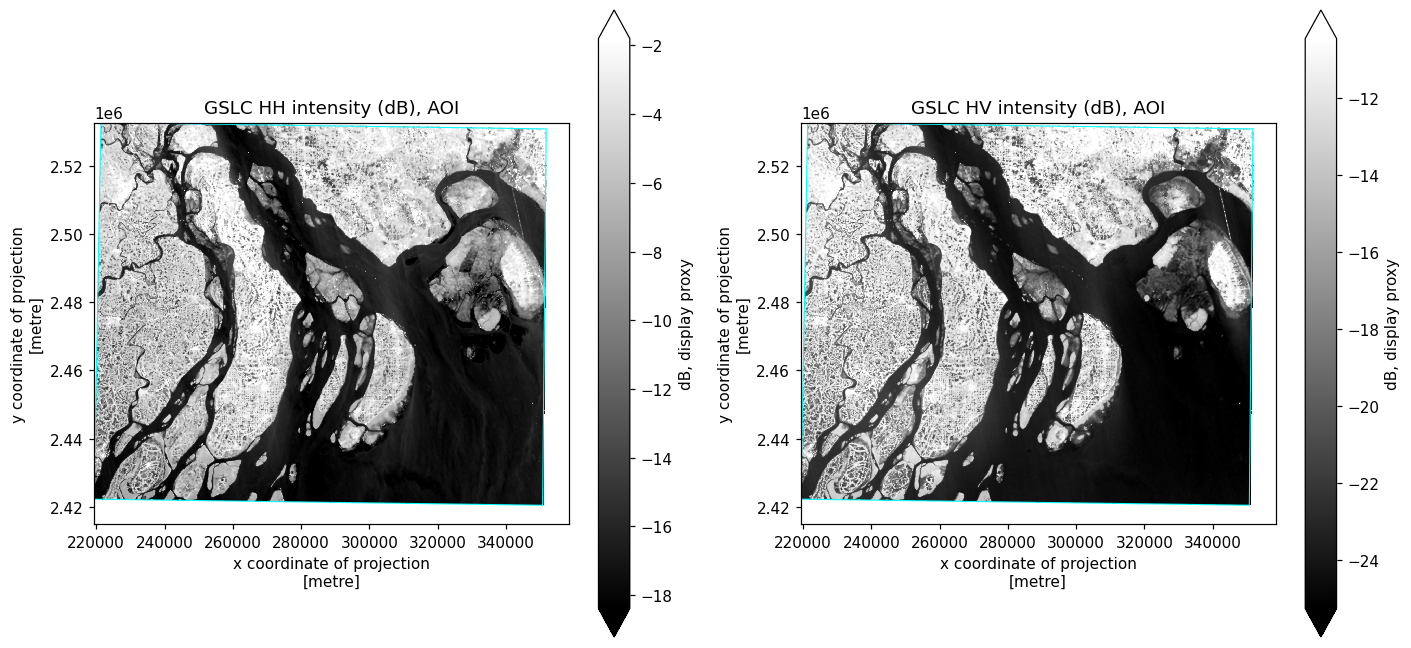

AOI output grid: 1,120 rows x 1,324 columns
CRS: EPSG:32646; source pixel spacing: 5 m


In [6]:
# Attach the GSLC's map CRS to the downsampled layers and clip them to the exact AOI
# polygon (not just the rectangular row/column window used to read the data), then
# plot the clipped HH/HV intensity.

# 1. GSLC is already geocoded onto a projected grid, so no radar-to-map resampling is
#    needed here: set_spatial_dims/write_crs just tell rioxarray which dims are x/y and
#    which CRS they are in, and rio.clip trims the rectangular window down to the
#    AOI polygon's actual shape (all_touched keeps partially covered edge pixels).
def georeference_and_clip(image):
    # tell rioxarray which dimensions are x and y, and attach the CRS
    return image.rio.set_spatial_dims(x_dim="x", y_dim="y").rio.write_crs(
        f"EPSG:{epsg}"
    ).rio.clip(aoi_grid.geometry, aoi_grid.crs, drop=True, all_touched=True)

# 2. Apply the same georeference-and-clip step to both intensity (dB) and phase
#    layers for each polarization, so all four end up on the identical AOI-clipped
#    grid used by the remaining cells.
hh_db_aoi = georeference_and_clip(hh_db)
hv_db_aoi = georeference_and_clip(hv_db)  # HV in dB, clipped to the AOI
hh_phase_aoi = georeference_and_clip(hh_phase)  # HH phase, clipped
hv_phase_aoi = georeference_and_clip(hv_phase)  # HV phase, clipped

# 3. Plot the clipped HH/HV intensity with robust (percentile-based) scaling and
#    overlay the AOI boundary to visually confirm the clip matches the polygon.
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, image, title in (  # the two images with their titles
    (axes[0], hh_db_aoi, "GSLC HH intensity (dB), AOI"),
    (axes[1], hv_db_aoi, "GSLC HV intensity (dB), AOI"),
):
    # show with a robust stretch
    image.plot.imshow(ax=ax, cmap="gray", robust=True, cbar_kwargs={"label": "dB, display proxy"})
    aoi_grid.boundary.plot(ax=ax, color="cyan", linewidth=0.7)  # AOI outline
    ax.set_title(title)  # title
    ax.set_aspect("equal")  # equal scale
plt.tight_layout()  # arrange
plt.show()  # draw

print(f"AOI output grid: {hh_db_aoi.sizes['y']:,} rows x {hh_db_aoi.sizes['x']:,} columns")  # grid size
print(f"CRS: {hh_db_aoi.rio.crs}; source pixel spacing: {x_spacing:g} m")  # CRS and pixel spacing

## HH/HV false-color RGB composite

Create a display composite using red = HH intensity in dB, green = HV intensity in dB, and blue = HH−HV in dB (the HH/HV power ratio expressed in decibels). The three channels are contrast-stretched independently from the 2nd to 98th percentile. This is a visualization convention only.


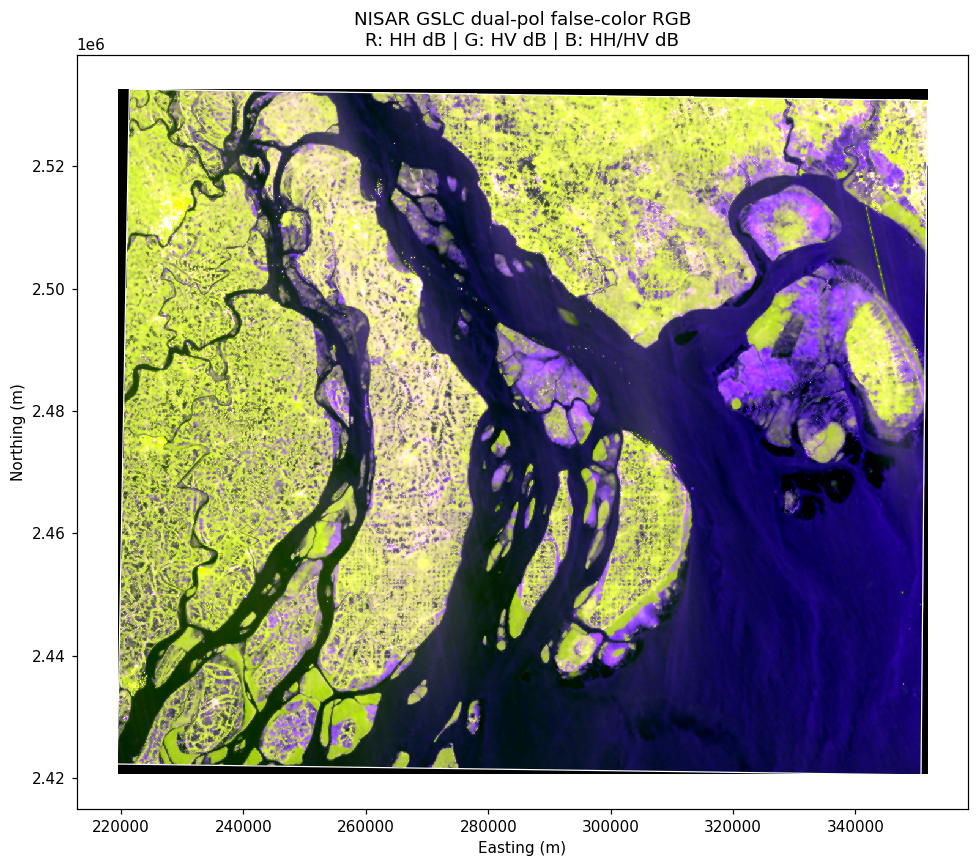

In [7]:
# Build an HH/HV/HH-HV false-color RGB composite for visual comparison of co- and
# cross-polarized response, with each channel independently percentile-stretched.

# 1. Work in plain float32 arrays (not xarray) for the per-channel stretch math. The
#    blue channel is the HH-HV ratio expressed in dB (a subtraction in log units), a
#    common dual-pol visualization convention that highlights contrast between
#    co-polarized and cross-polarized backscatter. valid_rgb marks pixels where both
#    source bands are finite.
hh_values = hh_db_aoi.values.astype("float32")
hv_values = hv_db_aoi.values.astype("float32")  # HV in dB
ratio_values = hh_values - hv_values  # HH minus HV (dB)
valid_rgb = np.isfinite(hh_values) & np.isfinite(hv_values)  # pixels valid in both

# stretch one channel to [0, 1] between percentiles of its valid values
def stretch_channel(values, mask, percentiles=(2, 98)):
    # 2. Compute the stretch percentiles only from valid (finite, AOI) pixels, then
    #    clip and rescale the full array to 0-1 for display. A degenerate channel
    #    (no spread between low and high) is returned as all zeros rather than
    #    dividing by zero.
    finite_values = values[mask]
    if finite_values.size == 0:  # no valid values
        raise ValueError("RGB channel has no finite data inside the AOI")  # stop with a clear message
    low, high = np.percentile(finite_values, percentiles)  # percentile limits
    if high <= low:  # constant channel
        return np.zeros(values.shape, dtype="float32")  # return zeros
    return np.clip((values - low) / (high - low), 0, 1).astype("float32")  # stretch to [0, 1]

# 3. Stack the three independently stretched channels into an (rows, columns, 3) RGB
#    array: red = HH, green = HV, blue = HH-HV ratio in dB. Pixels invalid in either
#    source band are forced to black rather than left with a partial/misleading color.
rgb = np.stack((
    stretch_channel(hh_values, valid_rgb),
    stretch_channel(hv_values, valid_rgb),
    stretch_channel(ratio_values, valid_rgb),
), axis=-1)
rgb[~valid_rgb] = 0  # no-data pixels in black

# 4. Plot the composite in map coordinates (using the AOI-clipped x/y axes as the
#    image extent) with the AOI boundary overlaid for reference.
x = hh_db_aoi.x.values
y = hh_db_aoi.y.values  # northing values
fig, ax = plt.subplots(figsize=(9, 8))  # one panel
# the RGB composite in map coordinates
ax.imshow(rgb, extent=(x.min(), x.max(), y.min(), y.max()), origin="upper", interpolation="nearest")
aoi_grid.boundary.plot(ax=ax, color="white", linewidth=0.8)  # AOI outline
ax.set(xlabel="Easting (m)", ylabel="Northing (m)",  # axis labels and title
       title="NISAR GSLC dual-pol false-color RGB\nR: HH dB | G: HV dB | B: HH/HV dB")
ax.set_aspect("equal")  # equal scale
plt.tight_layout()  # arrange
plt.show()  # draw

## Optionally export AOI quick looks

Exports are disabled by default. These downsampled intensity/phase images are visualization layers, not calibrated backscatter or analysis-ready interferometric outputs.


In [8]:
# Optionally write the AOI quick-look layers to disk as GeoTIFFs; disabled by default
# so running the notebook does not create files unexpectedly.

# 1. Flip this flag to True to export. Nothing is written otherwise.
WRITE_OUTPUTS = False
if WRITE_OUTPUTS:  # only when output writing is switched on
    # 2. Write each AOI-clipped intensity (dB) and wrapped-phase layer to its own
    #    LZW-compressed GeoTIFF under a dedicated quick-look output folder. These are
    #    the same display-oriented arrays plotted above, not calibrated backscatter
    #    or analysis-ready interferometric products.
    output_dir = DATA_DIR / "gslc_quicklooks"
    output_dir.mkdir(parents=True, exist_ok=True)  # create the output folder
    # save HH intensity in dB
    hh_db_aoi.rio.to_raster(output_dir / "NISAR_GSLC_HH_intensity_db_quicklook.tif", compress="LZW")
    # save HV intensity in dB
    hv_db_aoi.rio.to_raster(output_dir / "NISAR_GSLC_HV_intensity_db_quicklook.tif", compress="LZW")
    # save HH phase
    hh_phase_aoi.rio.to_raster(output_dir / "NISAR_GSLC_HH_wrapped_phase_quicklook.tif", compress="LZW")
    # save HV phase
    hv_phase_aoi.rio.to_raster(output_dir / "NISAR_GSLC_HV_wrapped_phase_quicklook.tif", compress="LZW")
    print(f"Wrote quick looks to {output_dir.resolve()}")  # where the files were written

## Summary, exercises and references

**Summary**

- GSLC is a geocoded, complex Level-2 NISAR product; its HH/HV samples retain phase and use a map-projected coordinate grid.
- The workflow reads only the AOI window, masks invalid GSLC samples, and performs chunked complex multilooking to reduce memory use.
- GeoLattice Lee filtering and dB conversion support intensity visualization, while wrapped phase is displayed separately and remains distinct from displacement.
- HH/HV RGB helps compare co-polarized and cross-polarized spatial response, but its percentile stretches are display-only.
- For calibrated backscatter and terrain-flattened products, use the matching NISAR GCOV product. For deformation, use a rigorously co-registered multi-date interferometric workflow.

**Conclusion**

This example demonstrates a practical, memory-bounded way to inspect and visualize a large NISAR GSLC scene over the supplied coastal Bangladesh AOI. Since GSLC is already on a projected map grid, AOI extraction and georeferencing are simpler than for RSLC, while the complex samples still carry phase information. The derived intensity and wrapped-phase quick looks are useful for exploration, but do not replace the calibrated GCOV product or a complete multi-date InSAR analysis.

**Additional resources**

- [NASA NISAR mission data and products](https://nisar.jpl.nasa.gov/data/)
- [ASF DAAC NISAR dataset information](https://asf.alaska.edu/datasets/daac/nisar/)
- [NISAR Product Specification documentation](https://nisar.jpl.nasa.gov/data/documents/)
- [ISCE3 processing framework](https://github.com/isce-framework/isce3)
- [GeoLattice user guide](https://github.com/zia207/GeoLattice/blob/main/docs/USER_GUIDE.md)
- [GeoLattice NISAR reader and quick-look processing API](https://github.com/zia207/GeoLattice/blob/main/src/rsense/sar/nisar.py)

Check the product version, processing release, metadata, mask definitions, and official product documentation for the specific granule before using results quantitatively.
